In [1]:
import duckdb

con = duckdb.connect()

con.execute("""
    CREATE VIEW customers AS SELECT * FROM read_csv_auto('olist_customers_dataset.csv');
    CREATE VIEW orders AS SELECT * FROM read_csv_auto('olist_orders_dataset.csv');
    CREATE VIEW order_items AS SELECT * FROM read_csv_auto('olist_order_items_dataset.csv');
    CREATE VIEW payments AS SELECT * FROM read_csv_auto('olist_order_payments_dataset.csv');
    CREATE VIEW reviews AS SELECT * FROM read_csv_auto('olist_order_reviews_dataset.csv');
""")

print("Views created successfully!")

Views created successfully!


In [2]:
repeat_customers = con.execute("""
    SELECT 
        c.customer_unique_id,
        COUNT(DISTINCT o.order_id) AS total_orders,
        MIN(o.order_purchase_timestamp) AS first_order,
        MAX(o.order_purchase_timestamp) AS last_order
    FROM orders o
    JOIN customers c ON o.customer_id = c.customer_id
    WHERE o.order_status = 'delivered'
    GROUP BY c.customer_unique_id
    ORDER BY total_orders DESC
""").df()

repeat_customers.head(10)

,customer_unique_id,total_orders,first_order,last_order
0,8d50f5eadf50201ccdcedfb9e2ac8455,15,2017-06-18 22:56:48,2018-08-20 19:14:26
1,3e43e6105506432c953e165fb2acf44c,9,2017-09-18 18:53:15,2018-02-27 18:36:39
2,ca77025e7201e3b30c44b472ff346268,7,2017-10-09 12:34:39,2018-06-01 11:38:29
3,6469f99c1f9dfae7733b25662e7f1782,7,2017-09-19 01:02:44,2018-06-28 00:43:34
4,1b6c7548a2a1f9037c1fd3ddfed95f33,7,2017-11-13 16:44:41,2018-02-14 13:22:12
5,12f5d6e1cbf93dafd9dcc19095df0b3d,6,2017-01-05 14:18:03,2017-01-05 15:25:10
6,f0e310a6839dce9de1638e0fe5ab282a,6,2017-05-20 08:53:30,2018-04-05 09:04:45
7,47c1a3033b8b77b3ab6e109eb4d5fdf3,6,2017-08-07 14:14:22,2018-01-24 15:15:26
8,63cfc61cee11cbe306bff5857d00bfe4,6,2017-05-11 14:39:53,2018-05-28 17:20:02
9,dc813062e0fc23409cd255f7f53c7074,6,2017-07-01 04:22:21,2018-08-23 00:07:26


In [3]:
churn_summary = repeat_customers['total_orders'].value_counts(normalize=True).sort_index() * 100
print(churn_summary.head())

total_orders
1    96.999722
2     2.756057
3     0.193877
4     0.029992
5     0.009640
Name: proportion, dtype: float64


In [4]:
gap_data = con.execute("""
    WITH customer_orders AS (
        SELECT 
            c.customer_unique_id,
            o.order_purchase_timestamp,
            LAG(o.order_purchase_timestamp) OVER (
                PARTITION BY c.customer_unique_id 
                ORDER BY o.order_purchase_timestamp
            ) AS prev_order
        FROM orders o
        JOIN customers c ON o.customer_id = c.customer_id
        WHERE o.order_status = 'delivered'
    )
    SELECT 
        customer_unique_id,
        DATE_DIFF('day', prev_order, order_purchase_timestamp) AS gap_days
    FROM customer_orders
    WHERE prev_order IS NOT NULL
""").df()

print(gap_data['gap_days'].describe())
print("\n80th percentile:", gap_data['gap_days'].quantile(0.8))
print("90th percentile:", gap_data['gap_days'].quantile(0.9))

count    3120.000000
mean       79.147436
std       107.295465
min         0.000000
25%         0.000000
50%        29.000000
75%       122.000000
max       609.000000
Name: gap_days, dtype: float64

80th percentile: 154.0
90th percentile: 240.0999999999999


In [ ]:
gap_data_clean = gap_data[gap_data['gap_days'] > 0]

print(gap_data_clean['gap_days'].describe())
print("\n75th percentile:", gap_data_clean['gap_days'].quantile(0.75))
print("80th percentile:", gap_data_clean['gap_days'].quantile(0.80))
print("90th percentile:", gap_data_clean['gap_days'].quantile(0.90))

count    2230.000000
mean      110.735426
std       112.292035
min         1.000000
25%        22.000000
50%        69.000000
75%       169.000000
max       609.000000
Name: gap_days, dtype: float64

75th percentile: 169.0
80th percentile: 196.0
90th percentile: 280.0


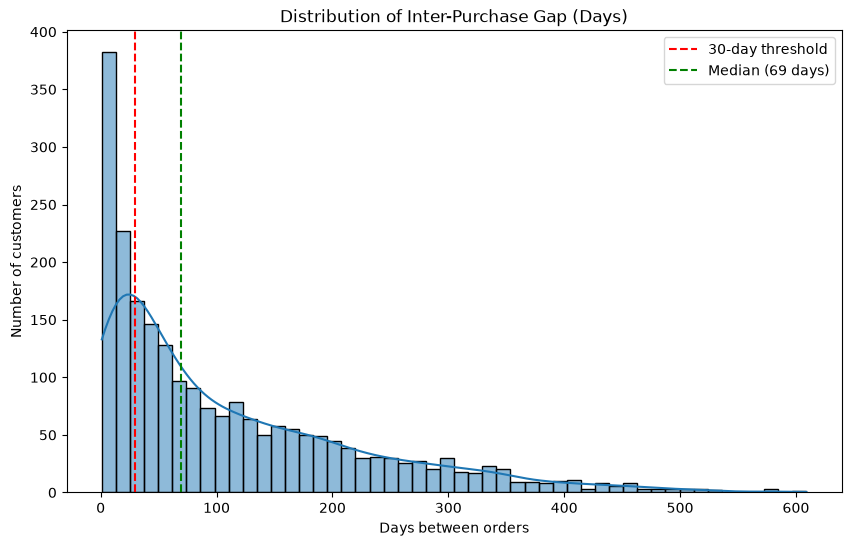

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))
sns.histplot(gap_data_clean['gap_days'], bins=50, kde=True)
plt.axvline(30, color='red', linestyle='--', label='30-day threshold')
plt.axvline(gap_data_clean['gap_days'].median(), color='green', linestyle='--', label='Median (69 days)')
plt.title('Distribution of Inter-Purchase Gap (Days)')
plt.xlabel('Days between orders')
plt.ylabel('Number of customers')
plt.legend()
plt.show()

In [7]:
con.execute("""
    CREATE VIEW products AS SELECT * FROM read_csv_auto('olist_products_dataset.csv');
""")

In [8]:
category_gap = con.execute("""
    WITH customer_category_orders AS (
        SELECT 
            c.customer_unique_id,
            p.product_category_name,
            o.order_purchase_timestamp,
            LAG(o.order_purchase_timestamp) OVER (
                PARTITION BY c.customer_unique_id, p.product_category_name
                ORDER BY o.order_purchase_timestamp
            ) AS prev_order
        FROM orders o
        JOIN customers c ON o.customer_id = c.customer_id
        JOIN order_items oi ON o.order_id = oi.order_id
        JOIN products p ON oi.product_id = p.product_id
        WHERE o.order_status = 'delivered'
    )
    SELECT 
        product_category_name,
        COUNT(*) AS repeat_purchases,
        MEDIAN(DATE_DIFF('day', prev_order, order_purchase_timestamp)) AS median_gap_days
    FROM customer_category_orders
    WHERE prev_order IS NOT NULL 
      AND DATE_DIFF('day', prev_order, order_purchase_timestamp) > 0
    GROUP BY product_category_name
    HAVING COUNT(*) >= 10
    ORDER BY median_gap_days DESC
""").df()

category_gap

,product_category_name,repeat_purchases,median_gap_days
0,cool_stuff,12,114.0
1,informatica_acessorios,58,66.5
2,esporte_lazer,125,54.0
3,beleza_saude,87,49.0
4,automotivo,30,44.0
5,cama_mesa_banho,140,42.0
6,brinquedos,34,40.0
7,ferramentas_jardim,24,35.5
8,pet_shop,16,35.0
9,fashion_bolsas_e_acessorios,43,34.0


In [9]:
category_gap_mean = con.execute("""
    WITH customer_category_orders AS (
        SELECT 
            c.customer_unique_id,
            p.product_category_name,
            o.order_purchase_timestamp,
            LAG(o.order_purchase_timestamp) OVER (
                PARTITION BY c.customer_unique_id, p.product_category_name
                ORDER BY o.order_purchase_timestamp
            ) AS prev_order
        FROM orders o
        JOIN customers c ON o.customer_id = c.customer_id
        JOIN order_items oi ON o.order_id = oi.order_id
        JOIN products p ON oi.product_id = p.product_id
        WHERE o.order_status = 'delivered'
    )
    SELECT 
        product_category_name,
        COUNT(*) AS repeat_purchases,
        ROUND(AVG(DATE_DIFF('day', prev_order, order_purchase_timestamp)), 1) AS mean_gap_days,
        MEDIAN(DATE_DIFF('day', prev_order, order_purchase_timestamp)) AS median_gap_days
    FROM customer_category_orders
    WHERE prev_order IS NOT NULL 
      AND DATE_DIFF('day', prev_order, order_purchase_timestamp) > 0
    GROUP BY product_category_name
    HAVING COUNT(*) >= 10
    ORDER BY mean_gap_days DESC
""").df()

category_gap_mean

,product_category_name,repeat_purchases,mean_gap_days,median_gap_days
0,cool_stuff,12,130.9,114.0
1,informatica_acessorios,58,104.8,66.5
2,cama_mesa_banho,140,87.8,42.0
3,esporte_lazer,125,76.8,54.0
4,utilidades_domesticas,43,75.5,26.0
5,beleza_saude,87,73.3,49.0
6,ferramentas_jardim,24,73.1,35.5
7,relogios_presentes,64,71.8,26.5
8,fashion_bolsas_e_acessorios,43,70.9,34.0
9,telefonia,35,68.5,29.0


In [10]:
max_date = con.execute("SELECT MAX(order_purchase_timestamp) AS max_date FROM orders").df()
print(max_date)

             max_date
0 2018-10-17 17:30:18


In [11]:
import pandas as pd

snapshot_date = pd.Timestamp('2018-10-17')
print("Snapshot date:", snapshot_date)

Snapshot date: 2018-10-17 00:00:00


In [ ]:
customer_recency = con.execute("""
    SELECT 
        c.customer_unique_id,
        COUNT(DISTINCT o.order_id) AS total_orders,
        MIN(o.order_purchase_timestamp) AS first_order,
        MAX(o.order_purchase_timestamp) AS last_order
    FROM orders o
    JOIN customers c ON o.customer_id = c.customer_id
    WHERE o.order_status = 'delivered'
    GROUP BY c.customer_unique_id
""").df()

# Here recency means days from the last order
customer_recency['last_order'] = pd.to_datetime(customer_recency['last_order'])
customer_recency['first_order'] = pd.to_datetime(customer_recency['first_order'])
customer_recency['recency_days'] = (snapshot_date - customer_recency['last_order']).dt.days

customer_recency['churned'] = (customer_recency['recency_days'] > 90).astype(int)

print(customer_recency['churned'].value_counts(normalize=True) * 100)
customer_recency.head(10)

churned
1    89.662375
0    10.337625
Name: proportion, dtype: float64


,customer_unique_id,total_orders,first_order,last_order,recency_days,churned
0,e6aede5b2818df1b512845c729cf7463,1,2017-11-29 13:49:23,2017-11-29 13:49:23,321,1
1,f86c68d3fd5ce93aa8b7e7d6e205f575,1,2018-06-28 12:47:48,2018-06-28 12:47:48,110,1
2,75c23d066292aeca5ccb1db8ff8bf883,1,2018-03-29 16:00:06,2018-03-29 16:00:06,201,1
3,55ce5d7beec2d30e0f4d4decdbafded0,1,2018-01-25 14:10:51,2018-01-25 14:10:51,264,1
4,f5d6d5ca5ebb427953236adb8e91aea5,1,2018-01-09 22:17:09,2018-01-09 22:17:09,280,1
5,b4440223bd5fc71d0e9e491dfc2a53a0,1,2018-06-22 13:12:28,2018-06-22 13:12:28,116,1
6,3329202f1e357ad78ad4bbc14f3f658a,1,2017-07-15 12:24:22,2017-07-15 12:24:22,458,1
7,ee9fa2efc23d0a26e507906773e0ff1d,1,2018-06-13 02:32:34,2018-06-13 02:32:34,125,1
8,893872dee0da455a53fdc742b2884fa9,1,2018-06-19 22:37:17,2018-06-19 22:37:17,119,1
9,49afeec74ee36fc6e5582ccd16111a14,2,2017-11-17 13:00:45,2017-11-17 13:16:48,333,1


In [ ]:
# New vs Repeat
customer_recency['customer_type'] = customer_recency['total_orders'].apply(
    lambda x: 'Repeat' if x >= 2 else 'New'
)

# Churn rate of every segment
segment_churn = customer_recency.groupby('customer_type')['churned'].agg(['mean', 'count']) * 100
segment_churn['mean'] = segment_churn['mean']  # already %
segment_churn.rename(columns={'mean': 'churn_rate_%', 'count': 'customer_count'}, inplace=True)
segment_churn['customer_count'] = segment_churn['customer_count'] / 100  # fix count scaling

print(segment_churn)

               churn_rate_%  customer_count
customer_type                              
New               89.691575         90557.0
Repeat            88.718315          2801.0


In [ ]:
# Finding average gap of repeating customers
avg_gap_per_customer = gap_data_clean.groupby('customer_unique_id')['gap_days'].mean().reset_index()
avg_gap_per_customer.columns = ['customer_unique_id', 'avg_historical_gap']

# Merge with churn status
repeat_analysis = customer_recency[customer_recency['customer_type'] == 'Repeat'].merge(
    avg_gap_per_customer, on='customer_unique_id', how='left'
)

# Comparison of average gaps of repeating vs one time customer
print(repeat_analysis.groupby('churned')['avg_historical_gap'].describe())

          count        mean         std  min   25%    50%    75%    max
churned                                                                
0         280.0  158.819065  141.243408  1.0  33.5  128.5  246.0  583.0
1        1735.0  106.588348  105.664218  1.0  23.0   71.0  160.0  609.0


In [ ]:
# Gap Ratio = current recency / apna historical average gap
repeat_analysis['gap_ratio'] = repeat_analysis['recency_days'] / repeat_analysis['avg_historical_gap']

# Focusing only on churned repeat customers (this is our win-back target)
at_risk = repeat_analysis[repeat_analysis['churned'] == 1].copy()

# High priority to those customers whose average gap is 2x more than there normal average gap.
at_risk['priority'] = at_risk['gap_ratio'].apply(
    lambda x: 'High' if x >= 2 else ('Medium' if x >= 1.2 else 'Low')
)

print(at_risk['priority'].value_counts())
print("\nSample high-priority customers:")
at_risk[at_risk['priority'] == 'High'][
    ['customer_unique_id', 'total_orders', 'avg_historical_gap', 'recency_days', 'gap_ratio']
].sort_values('gap_ratio', ascending=False).head(10)

priority
Low       1121
High      1120
Medium     244
Name: count, dtype: int64

Sample high-priority customers:


,customer_unique_id,total_orders,avg_historical_gap,recency_days,gap_ratio
1004,f7b62c75467e8ce080b201667cbbc274,2,1.0,739,739.0
289,cfdaaa0caea59b06efb4b0fb8c700684,2,1.0,592,592.0
2480,db539c729198334582efc7b53c803c79,2,1.0,560,560.0
885,25a560b9a6006157838aab1bdbd68624,4,1.0,555,555.0
1996,582183483d33018384b309d31c45f353,2,1.0,541,541.0
2573,947c249c7f31f3eae2bd05454e1b2040,2,1.0,522,522.0
2515,917de9fb824d070a7f1f4db097cbea8d,2,1.0,515,515.0
779,971e2252d557c5f6b2de810f6fcd52eb,2,1.0,462,462.0
2512,1015173479527a15ccb63606a74f404e,2,1.0,406,406.0
1679,2b19910e856b2ba3e7257e63a093a3df,2,1.0,385,385.0


In [ ]:
# Taking only those customers who have 3+ orders so that average gap looks logical
reliable_customers = repeat_analysis[repeat_analysis['total_orders'] >= 3].copy()

at_risk_reliable = reliable_customers[reliable_customers['churned'] == 1].copy()

at_risk_reliable['priority'] = at_risk_reliable['gap_ratio'].apply(
    lambda x: 'High' if x >= 2 else ('Medium' if x >= 1.2 else 'Low')
)

print(at_risk_reliable['priority'].value_counts())
print("\nSample high-priority customers (reliable):")
at_risk_reliable[at_risk_reliable['priority'] == 'High'][
    ['customer_unique_id', 'total_orders', 'avg_historical_gap', 'recency_days', 'gap_ratio']
].sort_values('gap_ratio', ascending=False).head(10)

priority
High      121
Low        45
Medium     29
Name: count, dtype: int64

Sample high-priority customers (reliable):


,customer_unique_id,total_orders,avg_historical_gap,recency_days,gap_ratio
885,25a560b9a6006157838aab1bdbd68624,4,1.0,555,555.000000
820,a40096fc0a3862e9e12bc55b5f8e6ab2,3,1.0,370,370.000000
1568,e68e1b61896163cdd7f8e07b2ae814c9,3,1.0,182,182.000000
2314,97bc08e526795b17e1d4f642f77ae304,3,3.0,435,145.000000
1317,cbd08b04b3f301152b7570da5e9c8cc4,3,3.0,395,131.666667
266,c76762dfb642ac154475239639f7f8f4,3,9.0,615,68.333333
1050,c4fe9fc8b5e1b4f9992db983d0429854,3,8.0,528,66.000000
223,a239b8e2fbce33780f1f1912e2ee5275,4,11.0,606,55.090909
501,b08fab27d47a1eb6deda07bfd965ad43,4,7.5,392,52.266667
2194,083ca1aa470c280236380973a48f77c6,3,9.5,426,44.842105


In [17]:
review_churn_check = con.execute("""
    WITH customer_reviews AS (
        SELECT 
            c.customer_unique_id,
            AVG(r.review_score) AS avg_review_score
        FROM orders o
        JOIN customers c ON o.customer_id = c.customer_id
        JOIN reviews r ON o.order_id = r.order_id
        WHERE o.order_status = 'delivered'
        GROUP BY c.customer_unique_id
    )
    SELECT customer_unique_id, avg_review_score
    FROM customer_reviews
""").df()

merged_review = customer_recency.merge(review_churn_check, on='customer_unique_id', how='inner')

merged_review['review_bucket'] = pd.cut(
    merged_review['avg_review_score'], 
    bins=[0, 2, 3, 4, 5], 
    labels=['1-2 (Bad)', '2-3 (Below Avg)', '3-4 (Good)', '4-5 (Great)']
)

print(merged_review.groupby('review_bucket')['churned'].agg(['mean', 'count']))

                     mean  count
review_bucket                   
1-2 (Bad)        0.923123  11759
2-3 (Below Avg)  0.915191   7794
3-4 (Good)       0.900343  18383
4-5 (Great)      0.886645  54819


In [18]:
at_risk_reliable['gap_ratio_capped'] = at_risk_reliable['gap_ratio'].clip(upper=10)

In [19]:
at_risk_reliable[['customer_unique_id', 'total_orders', 'avg_historical_gap', 'recency_days', 'gap_ratio', 'gap_ratio_capped']].sort_values('gap_ratio', ascending=False).head(10)

,customer_unique_id,total_orders,avg_historical_gap,recency_days,gap_ratio,gap_ratio_capped
885,25a560b9a6006157838aab1bdbd68624,4,1.0,555,555.000000,10.0
820,a40096fc0a3862e9e12bc55b5f8e6ab2,3,1.0,370,370.000000,10.0
1568,e68e1b61896163cdd7f8e07b2ae814c9,3,1.0,182,182.000000,10.0
2314,97bc08e526795b17e1d4f642f77ae304,3,3.0,435,145.000000,10.0
1317,cbd08b04b3f301152b7570da5e9c8cc4,3,3.0,395,131.666667,10.0
266,c76762dfb642ac154475239639f7f8f4,3,9.0,615,68.333333,10.0
1050,c4fe9fc8b5e1b4f9992db983d0429854,3,8.0,528,66.000000,10.0
223,a239b8e2fbce33780f1f1912e2ee5275,4,11.0,606,55.090909,10.0
501,b08fab27d47a1eb6deda07bfd965ad43,4,7.5,392,52.266667,10.0
2194,083ca1aa470c280236380973a48f77c6,3,9.5,426,44.842105,10.0


In [ ]:
cohort_data = con.execute("""
    SELECT 
        c.customer_unique_id,
        o.order_id,
        o.order_purchase_timestamp
    FROM orders o
    JOIN customers c ON o.customer_id = c.customer_id
    WHERE o.order_status = 'delivered'
""").df()

cohort_data['order_purchase_timestamp'] = pd.to_datetime(cohort_data['order_purchase_timestamp'])

# Every order's month
cohort_data['order_month'] = cohort_data['order_purchase_timestamp'].dt.to_period('M')

# Every customer's first purchase month (cohort)
cohort_data['cohort_month'] = cohort_data.groupby('customer_unique_id')['order_purchase_timestamp'].transform('min').dt.to_period('M')

# Here cohort index means how many months have passed after first purchase (0, 1, 2, 3...)
cohort_data['cohort_index'] = (cohort_data['order_month'] - cohort_data['cohort_month']).apply(lambda x: x.n)

cohort_data.head()

,customer_unique_id,order_id,order_purchase_timestamp,order_month,cohort_month,cohort_index
0,e6aede5b2818df1b512845c729cf7463,0b339dee90210409b715a9f2b6af29a7,2017-11-29 13:49:23,2017-11,2017-11,0
1,b168e38b8070518dc32151b68c996fd6,2149fe82b3e2d55f500ffe8406412733,2018-04-28 00:21:17,2018-04,2018-04,0
2,7bb854844864db3e6321acdc15e1066b,b9224c19c5ea3ae062a0141931846476,2017-06-20 14:21:18,2017-06,2017-06,0
3,bc68dfa77e201dc856450d8d919e8343,f6586a410980be02b8a408eb2d0a5c21,2017-05-16 22:42:57,2017-05,2017-05,0
4,0c85013ac2f907200089cd3461382a06,3ce8c5cf3d6b4356d90656b6ac73ab9a,2017-07-10 21:37:19,2017-07,2017-07,0


In [21]:
cohort_data[cohort_data['cohort_index'] > 0].head(10)

,customer_unique_id,order_id,order_purchase_timestamp,order_month,cohort_month,cohort_index
49,2ac6f6d09c75bb721defa2eb7a4f52a1,6ca5c63fb52f32ccf5309fddb636c3a8,2017-10-31 00:48:08,2017-10,2017-09,1
138,d6db3091e8c13023bf1e6d367b8c0847,7b9bc6b76ad9656ca99e8e1f2a6d249b,2018-07-19 13:55:05,2018-07,2017-06,13
195,a5afb1cd8d3b8126d2d39a7a29880c09,741653b1b2d0d37c62f1a1f90e93f02d,2018-06-27 09:46:09,2018-06,2018-05,1
237,47a71b49f98984efd3c62cb213f977e8,fb502b9421eb6ab817d72fc973b7b708,2017-11-05 10:38:50,2017-11,2017-10,1
251,5941ba7f91b519d195e16e34fcf61bac,308cbbff78b182dfef86b37c94f10205,2018-06-03 10:40:05,2018-06,2017-10,8
464,5d923ccb7548741c453df5a825da2515,78319eed3d0e14a32693dcb23db4c0d6,2018-04-12 15:21:23,2018-04,2018-03,1
586,394ac4de8f3acb14253c177f0e15bc58,3a4e65de6ffd941f6a4ee824d472aabb,2018-08-15 18:01:23,2018-08,2017-12,8
656,544bd839b4e7f92a077c7bf2410f8b02,88e583db0e0c8c29a91c2c68a0ee82db,2017-08-21 01:36:56,2017-08,2017-04,4
666,cabef558b42bd1d2578afc81048e8415,b12077e26b8a52d9944ab81e165e5a20,2018-04-08 21:48:54,2018-04,2018-01,3
790,cc2bef54fa72102dca9777ff483f75a5,707c884622a611c1c2c7b247c01f0121,2018-07-05 14:48:43,2018-07,2017-10,9


In [ ]:
# How many unique customers are there in every combo of cohort_month + cohort_index
cohort_counts = cohort_data.groupby(['cohort_month', 'cohort_index'])['customer_unique_id'].nunique().reset_index()

# Pivot: rows = cohort_month, columns = cohort_index, values = customer count
cohort_pivot = cohort_counts.pivot(index='cohort_month', columns='cohort_index', values='customer_unique_id')

cohort_pivot

cohort_index,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,19,20
cohort_month,,,,,,,,,,,,,,,,,,,,
2016-09,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-10,262.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,1.0,NaN,1.0,NaN,1.0,NaN,1.0,NaN,1.0,2.0,2.0
2016-12,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-01,717.0,2.0,2.0,1.0,3.0,1.0,3.0,1.0,1.0,NaN,3.0,1.0,5.0,3.0,1.0,1.0,2.0,3.0,1.0,NaN
2017-02,1628.0,3.0,5.0,2.0,7.0,2.0,4.0,3.0,2.0,3.0,2.0,5.0,2.0,3.0,2.0,1.0,1.0,3.0,NaN,NaN
2017-03,2503.0,11.0,9.0,10.0,9.0,4.0,4.0,8.0,8.0,2.0,9.0,3.0,5.0,3.0,4.0,6.0,2.0,3.0,NaN,NaN
2017-04,2256.0,14.0,5.0,4.0,6.0,6.0,8.0,7.0,7.0,4.0,6.0,2.0,1.0,1.0,2.0,2.0,3.0,NaN,NaN,NaN
2017-05,3451.0,16.0,16.0,10.0,10.0,11.0,14.0,5.0,9.0,9.0,9.0,12.0,8.0,1.0,6.0,7.0,NaN,NaN,NaN,NaN
2017-06,3037.0,15.0,12.0,13.0,9.0,12.0,11.0,7.0,4.0,6.0,9.0,11.0,5.0,5.0,7.0,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Removing starting months because they have less information as well as misleading information
cohort_pivot_clean = cohort_pivot.drop(index=['2016-09', '2016-10', '2016-12'], errors='ignore')

# Percentage retention: Dividing every row from its columns-0 (cohort size)
cohort_size = cohort_pivot_clean.iloc[:, 0]
retention_pct = cohort_pivot_clean.divide(cohort_size, axis=0) * 100

retention_pct.round(1)

cohort_index,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,19,20
cohort_month,,,,,,,,,,,,,,,,,,,,
2017-01,100.0,0.3,0.3,0.1,0.4,0.1,0.4,0.1,0.1,NaN,0.4,0.1,0.7,0.4,0.1,0.1,0.3,0.4,0.1,NaN
2017-02,100.0,0.2,0.3,0.1,0.4,0.1,0.2,0.2,0.1,0.2,0.1,0.3,0.1,0.2,0.1,0.1,0.1,0.2,NaN,NaN
2017-03,100.0,0.4,0.4,0.4,0.4,0.2,0.2,0.3,0.3,0.1,0.4,0.1,0.2,0.1,0.2,0.2,0.1,0.1,NaN,NaN
2017-04,100.0,0.6,0.2,0.2,0.3,0.3,0.4,0.3,0.3,0.2,0.3,0.1,0.0,0.0,0.1,0.1,0.1,NaN,NaN,NaN
2017-05,100.0,0.5,0.5,0.3,0.3,0.3,0.4,0.1,0.3,0.3,0.3,0.3,0.2,0.0,0.2,0.2,NaN,NaN,NaN,NaN
2017-06,100.0,0.5,0.4,0.4,0.3,0.4,0.4,0.2,0.1,0.2,0.3,0.4,0.2,0.2,0.2,NaN,NaN,NaN,NaN,NaN
2017-07,100.0,0.5,0.3,0.2,0.3,0.2,0.3,0.1,0.2,0.3,0.2,0.3,0.1,0.2,NaN,NaN,NaN,NaN,NaN,NaN
2017-08,100.0,0.7,0.3,0.3,0.3,0.5,0.3,0.3,0.1,0.1,0.2,0.2,0.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-09,100.0,0.7,0.5,0.3,0.4,0.2,0.2,0.2,0.3,0.2,0.2,0.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


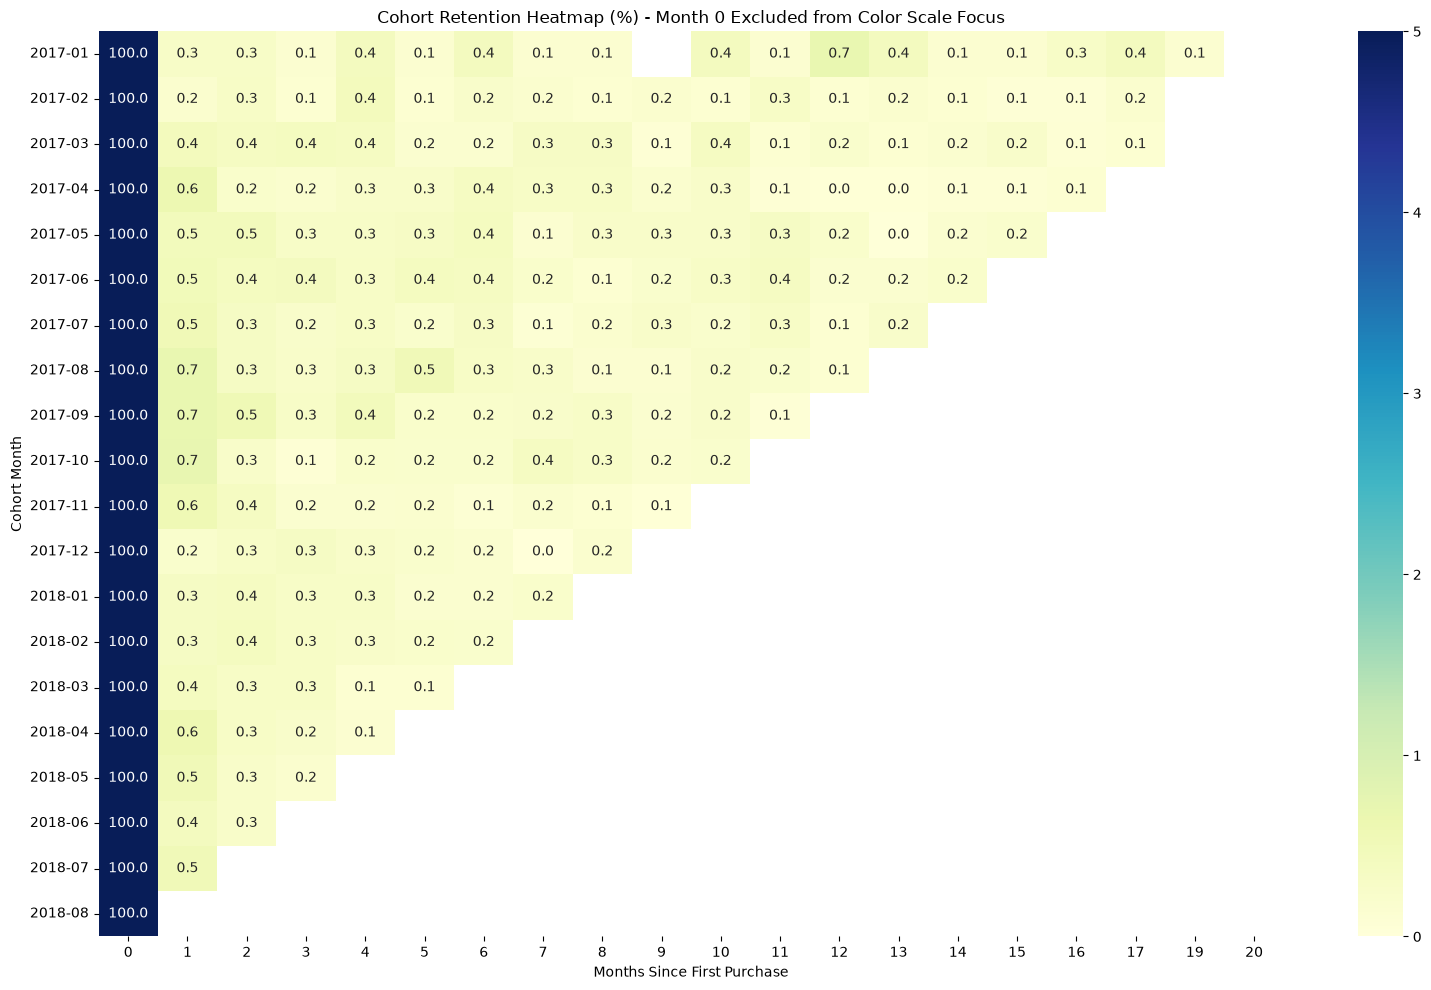

In [24]:
plt.figure(figsize=(16, 10))
sns.heatmap(retention_pct, annot=True, fmt='.1f', cmap='YlGnBu', vmin=0, vmax=5)
plt.title('Cohort Retention Heatmap (%) - Month 0 Excluded from Color Scale Focus')
plt.xlabel('Months Since First Purchase')
plt.ylabel('Cohort Month')
plt.tight_layout()
plt.show()

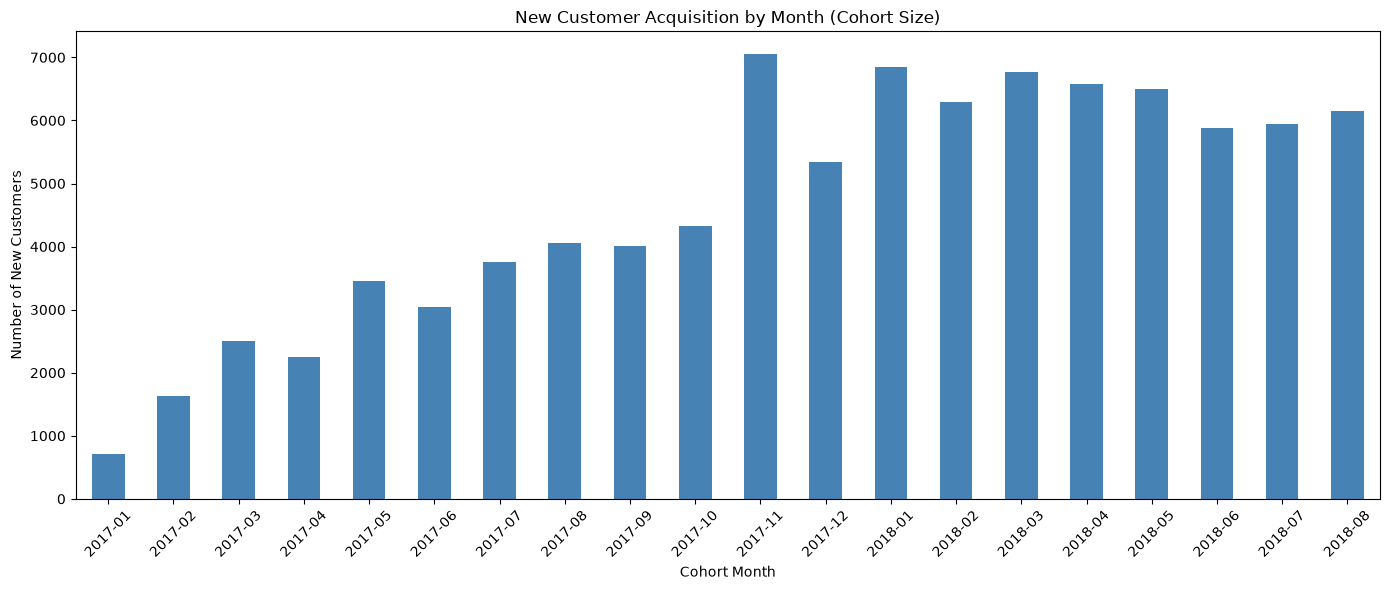

In [25]:
cohort_sizes = cohort_pivot_clean.iloc[:, 0]

plt.figure(figsize=(14,6))
cohort_sizes.plot(kind='bar', color='steelblue')
plt.title('New Customer Acquisition by Month (Cohort Size)')
plt.xlabel('Cohort Month')
plt.ylabel('Number of New Customers')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Step A: Finding customer value
customer_value = con.execute("""
    SELECT 
        c.customer_unique_id,
        SUM(p.payment_value) AS total_spend
    FROM orders o
    JOIN customers c ON o.customer_id = c.customer_id
    JOIN payments p ON o.order_id = p.order_id
    WHERE o.order_status = 'delivered'
    GROUP BY c.customer_unique_id
""").df()

median_spend = customer_value['total_spend'].median()
customer_value['value_segment'] = customer_value['total_spend'].apply(
    lambda x: 'High-value' if x >= median_spend else 'Low-value'
)

print("Median spend:", median_spend)
print(customer_value['value_segment'].value_counts())

# Step B: Merging with cohort data
cohort_data_value = cohort_data.merge(customer_value[['customer_unique_id','value_segment']], on='customer_unique_id', how='left')

# Step C: Different cohort pivot + retention % for every segment
def build_retention(df):
    counts = df.groupby(['cohort_month','cohort_index'])['customer_unique_id'].nunique().reset_index()
    pivot = counts.pivot(index='cohort_month', columns='cohort_index', values='customer_unique_id')
    pivot = pivot.drop(index=['2016-09','2016-10','2016-12'], errors='ignore')
    size = pivot.iloc[:,0]
    return pivot.divide(size, axis=0) * 100

high_value_retention = build_retention(cohort_data_value[cohort_data_value['value_segment']=='High-value'])
low_value_retention = build_retention(cohort_data_value[cohort_data_value['value_segment']=='Low-value'])

print("High-value month-1 retention avg:", high_value_retention[1].mean().round(2), "%")
print("Low-value month-1 retention avg:", low_value_retention[1].mean().round(2), "%")

Median spend: 107.78
value_segment
High-value    46782
Low-value     46575
Name: count, dtype: int64
High-value month-1 retention avg: 0.82 %
Low-value month-1 retention avg: 0.14 %


In [27]:
funnel_data = con.execute("""
    SELECT 
        COUNT(DISTINCT order_id) AS total_orders,
        COUNT(DISTINCT CASE WHEN order_status = 'delivered' THEN order_id END) AS delivered_orders,
        COUNT(DISTINCT CASE WHEN order_delivered_customer_date IS NOT NULL 
                             AND order_estimated_delivery_date IS NOT NULL
                             AND order_delivered_customer_date > order_estimated_delivery_date 
                        THEN order_id END) AS late_deliveries
    FROM orders
""").df()

funnel_data

,total_orders,delivered_orders,late_deliveries
0,99441,96478,7827


In [28]:
late_churn_check = con.execute("""
    WITH customer_delivery AS (
        SELECT 
            c.customer_unique_id,
            MAX(CASE WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date 
                     THEN 1 ELSE 0 END) AS had_late_delivery
        FROM orders o
        JOIN customers c ON o.customer_id = c.customer_id
        WHERE o.order_status = 'delivered'
        GROUP BY c.customer_unique_id
    )
    SELECT customer_unique_id, had_late_delivery
    FROM customer_delivery
""").df()

# Merge with churn status
merged = customer_recency.merge(late_churn_check, on='customer_unique_id', how='inner')

churn_by_delivery = merged.groupby('had_late_delivery')['churned'].mean() * 100
print(churn_by_delivery)

had_late_delivery
0    89.707549
1    89.164844
Name: churned, dtype: float64


In [29]:
first_order_experience = con.execute("""
    WITH customer_orders AS (
        SELECT 
            c.customer_unique_id,
            COUNT(DISTINCT o.order_id) AS total_orders
        FROM orders o
        JOIN customers c ON o.customer_id = c.customer_id
        WHERE o.order_status = 'delivered'
        GROUP BY c.customer_unique_id
    ),
    first_order AS (
        SELECT 
            c.customer_unique_id,
            o.order_id,
            o.order_delivered_customer_date,
            o.order_estimated_delivery_date,
            r.review_score,
            ROW_NUMBER() OVER (PARTITION BY c.customer_unique_id ORDER BY o.order_purchase_timestamp) AS rn
        FROM orders o
        JOIN customers c ON o.customer_id = c.customer_id
        LEFT JOIN reviews r ON o.order_id = r.order_id
        WHERE o.order_status = 'delivered'
    )
    SELECT 
        CASE WHEN co.total_orders = 1 THEN 'One-time' ELSE 'Repeat' END AS customer_type,
        AVG(fo.review_score) AS avg_first_order_review,
        AVG(CASE WHEN fo.order_delivered_customer_date > fo.order_estimated_delivery_date THEN 1 ELSE 0 END) * 100 AS pct_late_first_delivery
    FROM customer_orders co
    JOIN first_order fo ON co.customer_unique_id = fo.customer_unique_id AND fo.rn = 1
    GROUP BY CASE WHEN co.total_orders = 1 THEN 'One-time' ELSE 'Repeat' END
""").df()

first_order_experience

,customer_type,avg_first_order_review,pct_late_first_delivery
0,One-time,4.151962,8.186004
1,Repeat,4.195683,6.711889


In [30]:
payment_check = con.execute("""
    WITH customer_orders AS (
        SELECT 
            c.customer_unique_id,
            COUNT(DISTINCT o.order_id) AS total_orders
        FROM orders o
        JOIN customers c ON o.customer_id = c.customer_id
        WHERE o.order_status = 'delivered'
        GROUP BY c.customer_unique_id
    ),
    first_order_payment AS (
        SELECT 
            c.customer_unique_id,
            o.order_id,
            p.payment_installments,
            p.payment_type,
            p.payment_value,
            ROW_NUMBER() OVER (PARTITION BY c.customer_unique_id ORDER BY o.order_purchase_timestamp) AS rn
        FROM orders o
        JOIN customers c ON o.customer_id = c.customer_id
        JOIN payments p ON o.order_id = p.order_id
        WHERE o.order_status = 'delivered'
    )
    SELECT 
        CASE WHEN co.total_orders = 1 THEN 'One-time' ELSE 'Repeat' END AS customer_type,
        AVG(fop.payment_value) AS avg_first_order_value,
        AVG(fop.payment_installments) AS avg_installments
    FROM customer_orders co
    JOIN first_order_payment fop ON co.customer_unique_id = fop.customer_unique_id AND fop.rn = 1
    GROUP BY CASE WHEN co.total_orders = 1 THEN 'One-time' ELSE 'Repeat' END
""").df()

payment_check

,customer_type,avg_first_order_value,avg_installments
0,Repeat,142.621225,3.293467
1,One-time,158.131159,2.889074


In [31]:
funnel = con.execute("""
    WITH customer_order_counts AS (
        SELECT 
            c.customer_unique_id,
            COUNT(DISTINCT o.order_id) AS total_orders
        FROM orders o
        JOIN customers c ON o.customer_id = c.customer_id
        WHERE o.order_status = 'delivered'
        GROUP BY c.customer_unique_id
    )
    SELECT 
        SUM(CASE WHEN total_orders >= 1 THEN 1 ELSE 0 END) AS reached_1st_order,
        SUM(CASE WHEN total_orders >= 2 THEN 1 ELSE 0 END) AS reached_2nd_order,
        SUM(CASE WHEN total_orders >= 3 THEN 1 ELSE 0 END) AS reached_3rd_order,
        SUM(CASE WHEN total_orders >= 4 THEN 1 ELSE 0 END) AS reached_4th_order,
        SUM(CASE WHEN total_orders >= 5 THEN 1 ELSE 0 END) AS reached_5th_order
    FROM customer_order_counts
""").df()

funnel

,reached_1st_order,reached_2nd_order,reached_3rd_order,reached_4th_order,reached_5th_order
0,93358.0,2801.0,228.0,47.0,19.0


In [32]:
stages = ['reached_1st_order', 'reached_2nd_order', 'reached_3rd_order', 'reached_4th_order', 'reached_5th_order']
values = funnel[stages].iloc[0].values

funnel_df = pd.DataFrame({
    'stage': ['1st Order', '2nd Order', '3rd Order', '4th Order', '5th Order'],
    'customers': values
})

funnel_df['pct_of_total'] = (funnel_df['customers'] / funnel_df['customers'].iloc[0] * 100).round(2)
funnel_df['drop_from_previous_%'] = (100 - (funnel_df['customers'] / funnel_df['customers'].shift(1) * 100)).round(2)

funnel_df

,stage,customers,pct_of_total,drop_from_previous_%
0,1st Order,93358.0,100.00,NaN
1,2nd Order,2801.0,3.00,97.00
2,3rd Order,228.0,0.24,91.86
3,4th Order,47.0,0.05,79.39
4,5th Order,19.0,0.02,59.57


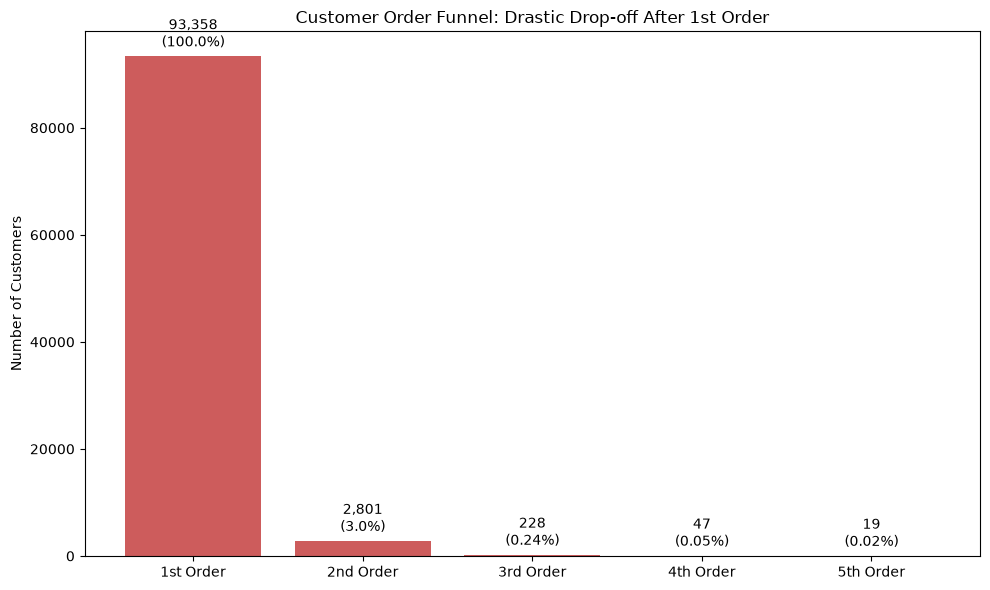

In [33]:
plt.figure(figsize=(10,6))
plt.bar(funnel_df['stage'], funnel_df['customers'], color='indianred')
for i, v in enumerate(funnel_df['customers']):
    plt.text(i, v + max(funnel_df['customers'])*0.02, f"{v:,.0f}\n({funnel_df['pct_of_total'].iloc[i]}%)", ha='center')
plt.title('Customer Order Funnel: Drastic Drop-off After 1st Order')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

In [34]:
import os
os.makedirs('powerbi_exports', exist_ok=True)

customer_recency.to_csv('powerbi_exports/customer_recency.csv', index=False)
retention_pct.to_csv('powerbi_exports/cohort_retention_pct.csv')
funnel_df.to_csv('powerbi_exports/funnel.csv', index=False)
at_risk_reliable.to_csv('powerbi_exports/at_risk_customers.csv', index=False)

print("Files exported to 'powerbi_exports' folder!")

Files exported to 'powerbi_exports' folder!


In [ ]:
print("Total columns:", len(retention_pct.columns))
print("Unique columns:", len(set(retention_pct.columns)))
print("Duplicate columns count:", retention_pct.columns.duplicated().sum())

print(retention_pct.columns.tolist())

Total columns: 20
Unique columns: 20
Duplicate columns count: 0
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 19, 20]


In [ ]:
high_value_export = high_value_retention.reset_index()
high_value_export['segment'] = 'High-value'

low_value_export = low_value_retention.reset_index()
low_value_export['segment'] = 'Low-value'

combined_value_retention = pd.concat([high_value_export, low_value_export], ignore_index=True)

combined_value_retention.to_csv('powerbi_exports/value_segment_retention.csv', index=False)
print("Exported successfully!")
print(combined_value_retention.head())

Exported successfully!
cohort_index cohort_month      0         1         2         3         4  \
0                 2017-01  100.0  0.531915  0.531915  0.265957  0.797872   
1                 2017-02  100.0  0.242718  0.606796  0.242718  0.849515   
2                 2017-03  100.0  0.731113  0.731113  0.731113  0.731113   
3                 2017-04  100.0  1.063830  0.354610  0.354610  0.531915   
4                 2017-05  100.0  0.753187  0.811124  0.579374  0.579374   

cohort_index         5         6         7         8  ...        11        12  \
0             0.265957  0.797872  0.265957  0.265957  ...  0.265957  1.063830   
1                  NaN  0.485437  0.242718  0.242718  ...  0.364078  0.242718   
2             0.324939  0.324939  0.568643  0.568643  ...  0.243704  0.406174   
3             0.531915  0.620567  0.443262  0.531915  ...  0.177305  0.088652   
4             0.579374  0.753187  0.289687  0.463499  ...  0.695249  0.463499   

cohort_index        13        14 

In [37]:
late_delivery_export = late_churn_check.merge(customer_recency[['customer_unique_id', 'churned']], on='customer_unique_id', how='inner')
late_delivery_export['had_late_delivery'] = late_delivery_export['had_late_delivery'].map({0: 'On-time', 1: 'Late'})
late_delivery_export.to_csv('powerbi_exports/late_delivery_churn.csv', index=False)

review_export = merged_review[['customer_unique_id', 'avg_review_score', 'review_bucket', 'churned']]
review_export.to_csv('powerbi_exports/review_churn.csv', index=False)

payment_export = payment_check.copy()
payment_export.to_csv('powerbi_exports/payment_comparison.csv', index=False)

print("All files exported!")

All files exported!
